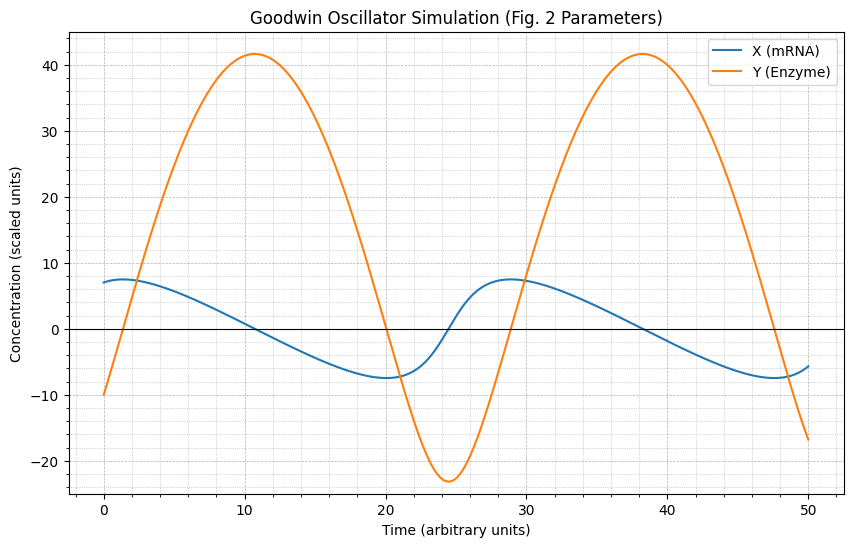

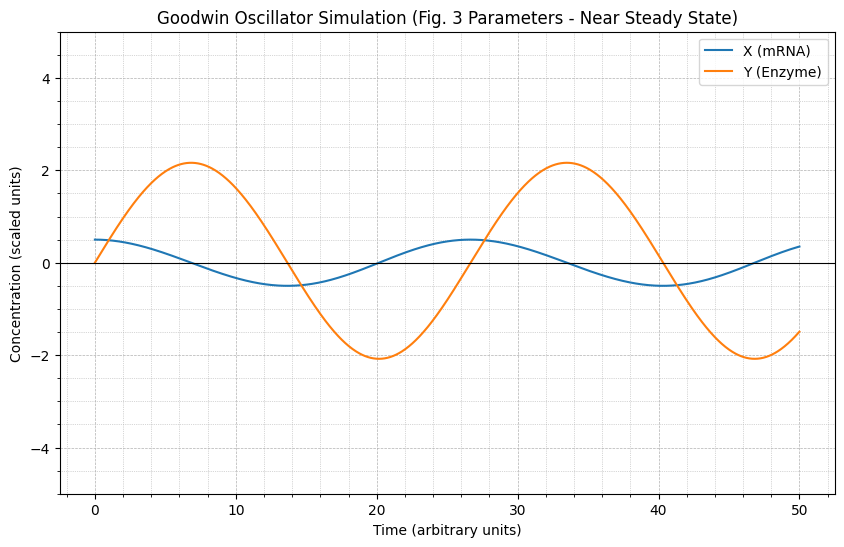

In [1]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# --- Model Definition (Equations 1) ---
def goodwin_oscillator(t, state, params):
    """
    Defines the system of differential equations for the Goodwin oscillator (Eq. 1).

    Args:
        t (float): Time (not explicitly used in these equations but required by solve_ivp).
        state (list or np.array): Current state vector [X, Y].
        params (dict): Dictionary containing the model parameters
                       (a, A, k, b, alpha, beta).

    Returns:
        list: List containing the derivatives [dX/dt, dY/dt].
    """
    X, Y = state
    a, A, k, b, alpha, beta = params['a'], params['A'], params['k'], params['b'], params['alpha'], params['beta']

    # Equation 1a: Rate of change of mRNA (X)
    # dX/dt = a / (A + k*Y) - b
    # We need to handle potential division by zero or issues if Y becomes very negative,
    # although the solver should ideally keep Y within reasonable bounds based on the dynamics.
    # Adding a small epsilon or checking the denominator might be needed in edge cases,
    # but let's stick to the paper's equation first.
    # Note: The paper uses Yi, Xi, ai etc. We'll drop the 'i' for a single oscillator.

    # Avoid division by zero or negative values in denominator if Y dips too low biologically
    denominator = A + k * Y
    if denominator <= 0:
         # Handle biologically unrealistic scenario, e.g., set rate to a minimum or zero
         # For this model as presented, negative Y is allowed for scaling.
         # If we were enforcing positivity, we'd adjust here.
         # Sticking to the paper's direct equations for now.
         pass # Keep original behavior

    dXdt = a / denominator - b


    # Equation 1b: Rate of change of Protein/Enzyme (Y)
    # dY/dt = alpha*X - beta
    dYdt = alpha * X - beta

    return [dXdt, dYdt]

# --- Simulation Parameters (from Fig. 2 description) ---
params_fig2 = {
    'a': 72.0,
    'A': 36.0,
    'k': 1.0,
    'b': 2.0,
    'alpha': 1.0,
    'beta': 0.0  # Beta is 0 in the example
}

# Initial conditions (from Fig. 2 description)
# Note: The paper uses (Xi)0=7, (Yi)0=-10. These seem like scaled values for the analog computer.
# Biological concentrations are non-negative. Starting near the steady state (0,0 for these params)
# with a small perturbation, or using the paper's values directly. Let's use the paper's values.
initial_state_fig2 = [7.0, -10.0]

# --- Simulation Time ---
# The paper mentions the computer interval is 1 sec, showing multiple cycles.
# Let's simulate for a longer duration to observe the oscillations clearly.
t_span_fig2 = [0, 50] # Simulate from t=0 to t=50 (adjust as needed)
t_eval_fig2 = np.linspace(t_span_fig2[0], t_span_fig2[1], 1000) # Points to evaluate solution

# --- Run Simulation ---
sol_fig2 = solve_ivp(
    fun=goodwin_oscillator,
    t_span=t_span_fig2,
    y0=initial_state_fig2,
    args=(params_fig2,),
    t_eval=t_eval_fig2,
    method='RK45', # Standard Runge-Kutta method
    dense_output=True,
    rtol=1e-6, # Add tolerance settings for potentially stiff systems
    atol=1e-8
)

# --- Plotting Results (Similar to Fig. 2) ---
plt.figure(figsize=(10, 6))
plt.plot(sol_fig2.t, sol_fig2.y[0], label='X (mRNA)') # mRNA concentration
plt.plot(sol_fig2.t, sol_fig2.y[1], label='Y (Enzyme)') # Enzyme concentration

# Add grid similar to the paper's figures
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.minorticks_on()
plt.grid(True, which='minor', linestyle=':', linewidth=0.5)

# Add labels and title
plt.xlabel("Time (arbitrary units)")
plt.ylabel("Concentration (scaled units)")
plt.title("Goodwin Oscillator Simulation (Fig. 2 Parameters)")
plt.legend()
# **** MODIFIED HERE: Increased upper Y limit ****
plt.ylim(-25, 45) # Adjust Y limits to ensure peaks are visible
plt.axhline(0, color='black', linewidth=0.8) # Add a line for zero reference

plt.show()

# --- Simulation for Fig. 3 (Near Steady State) ---
# Steady state for these parameters: X_bar = beta/alpha = 0/1 = 0
# Y_bar = (1/k) * (a/b - A) = (1/1) * (72/2 - 36) = 36 - 36 = 0
# Initial conditions near steady state (from Fig. 3 description)
initial_state_fig3 = [0.5, 0.0] # Paper uses X0=0.9, Y0=0

# Simulation time (might need shorter time or finer steps for small oscillations)
t_span_fig3 = [0, 50]
t_eval_fig3 = np.linspace(t_span_fig3[0], t_span_fig3[1], 1000)

# Run simulation for Fig. 3
sol_fig3 = solve_ivp(
    fun=goodwin_oscillator,
    t_span=t_span_fig3,
    y0=initial_state_fig3,
    args=(params_fig2,), # Use the same parameters as Fig. 2
    t_eval=t_eval_fig3,
    method='RK45',
    dense_output=True,
    rtol=1e-6, # Add tolerance settings
    atol=1e-8
)

# --- Plotting Results (Similar to Fig. 3) ---
plt.figure(figsize=(10, 6))
# The paper mentions Fig. 3 shows Y oscillation, which is nearly sinusoidal.
# Let's plot both X and Y, but expect Y to be more prominent initially.
plt.plot(sol_fig3.t, sol_fig3.y[0], label='X (mRNA)')
plt.plot(sol_fig3.t, sol_fig3.y[1], label='Y (Enzyme)')

# Add grid similar to the paper's figures
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.minorticks_on()
plt.grid(True, which='minor', linestyle=':', linewidth=0.5)

# Add labels and title
plt.xlabel("Time (arbitrary units)")
plt.ylabel("Concentration (scaled units)")
plt.title("Goodwin Oscillator Simulation (Fig. 3 Parameters - Near Steady State)")
plt.legend()
# Adjust Y limits for smaller oscillations
plt.ylim(-5, 5) # Zoom in compared to Fig 2 plot
plt.axhline(0, color='black', linewidth=0.8)

plt.show()


Solver status: 0


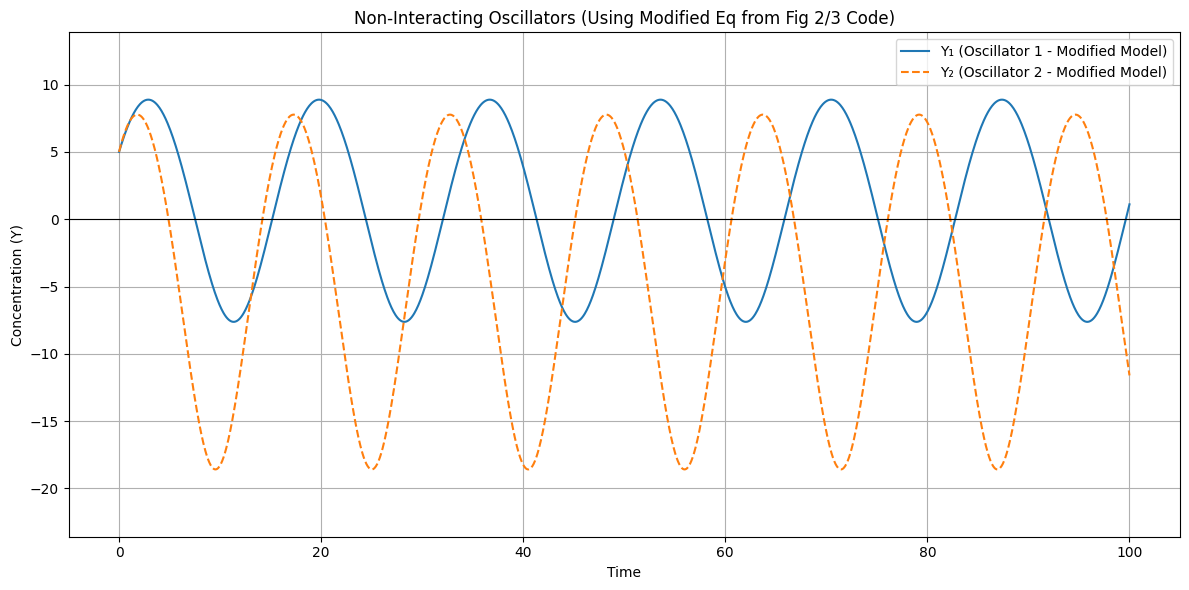

In [ ]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# --- Model Definition (Using YOUR working version for Fig 2/3) ---
def modified_goodwin_oscillator(t, state, params):
    """
    Uses the model structure from your working Fig 2/3 code:
    dX/dt = a / (A + k*Y) - b  (Constant decay b)
    dY/dt = alpha*X - beta*Y
    """
    X, Y = state
    a, A, k, b, alpha, beta = params['a'], params['A'], params['k'], params['b'], params['alpha'], params['beta']

    denominator = A + k * Y
    # Simple stabilization if denominator gets too small/negative
    epsilon = 1e-9
    if denominator <= epsilon:
        denominator = epsilon

    # --- Using the modified dX/dt from your code ---
    dXdt = a / denominator - b

    # Standard dY/dt
    dYdt = alpha * X - beta

    return [dXdt, dYdt]

# Define a function for the combined system of TWO independent modified oscillators
def two_independent_modified_oscillators(t, S_comb, p1, p2):
    """
    Simulates two independent oscillators using the modified_goodwin_oscillator function.
    S_comb = [X1, Y1, X2, Y2]
    p1 = parameters for oscillator 1
    p2 = parameters for oscillator 2
    """
    X1, Y1, X2, Y2 = S_comb

    # Calculate derivatives for oscillator 1
    dX1_dt, dY1_dt = modified_goodwin_oscillator(t, [X1, Y1], p1)

    # Calculate derivatives for oscillator 2
    dX2_dt, dY2_dt = modified_goodwin_oscillator(t, [X2, Y2], p2)

    return [dX1_dt, dY1_dt, dX2_dt, dY2_dt]


# --- Parameters for Figure 5 using YOUR model structure ---
# Non-interacting means k12=0, k21=0, handled by simulating independently
params_mod_osc1 = {
    'a': 360.0, 'A': 36.0, 'k': 1.0, 'b': 10.0, 'alpha': 0.5, 'beta': 0.0
}
params_mod_osc2 = {
    'a': 360.0, 'A': 43.0, 'k': 1.0, 'b': 10.0, 'alpha': 0.6, 'beta': 0.0
}


# --- Simulation ---
# Initial conditions - Start away from steady states (0, (a/b-A)/k)
# SS1 Y = (360/10 - 36)/1 = 0
# SS2 Y = (360/10 - 43)/1 = -7
# Let's start positive like before
S0_comb = [5, 5, 5, 5] # Initial state [X1, Y1, X2, Y2]

# Time span (adjust if needed)
t_max = 100
t_span = (0, t_max)
t_eval = np.linspace(t_span[0], t_span[1], 1500)

# Solve the combined ODE system
sol_combined_mod = solve_ivp(
    two_independent_modified_oscillators,
    t_span,
    S0_comb,
    args=(params_mod_osc1, params_mod_osc2),
    dense_output=True,
    t_eval=t_eval,
    method='RK45',
    atol=1e-8, rtol=1e-8
)

# Check solver status
print(f"Solver status: {sol_combined_mod.status}")
if sol_combined_mod.status != 0:
    print(f"Solver message: {sol_combined_mod.message}")

# Extract results
t = sol_combined_mod.t
X1, Y1, X2, Y2 = sol_combined_mod.y

# --- Plotting (Y variables, similar to Fig 5) ---
plt.figure(figsize=(12, 6))
plt.plot(t, Y1, label='Y₁ (Oscillator 1 - Modified Model)')
plt.plot(t, Y2, label='Y₂ (Oscillator 2 - Modified Model)', linestyle='--')
plt.grid(True)
plt.xlabel("Time")
plt.ylabel("Concentration (Y)")
plt.title("Non-Interacting Oscillators (Using Modified Eq from Fig 2/3 Code)")
plt.legend()
# Adjust Y limits based on results, allow potential negative values
min_y = min(np.min(Y1), np.min(Y2)) - 5
max_y = max(np.max(Y1), np.max(Y2)) + 5
plt.ylim(min_y, max_y)
#plt.ylim(-10, 50) # Optional manual adjustment
plt.axhline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

Solver status: 0


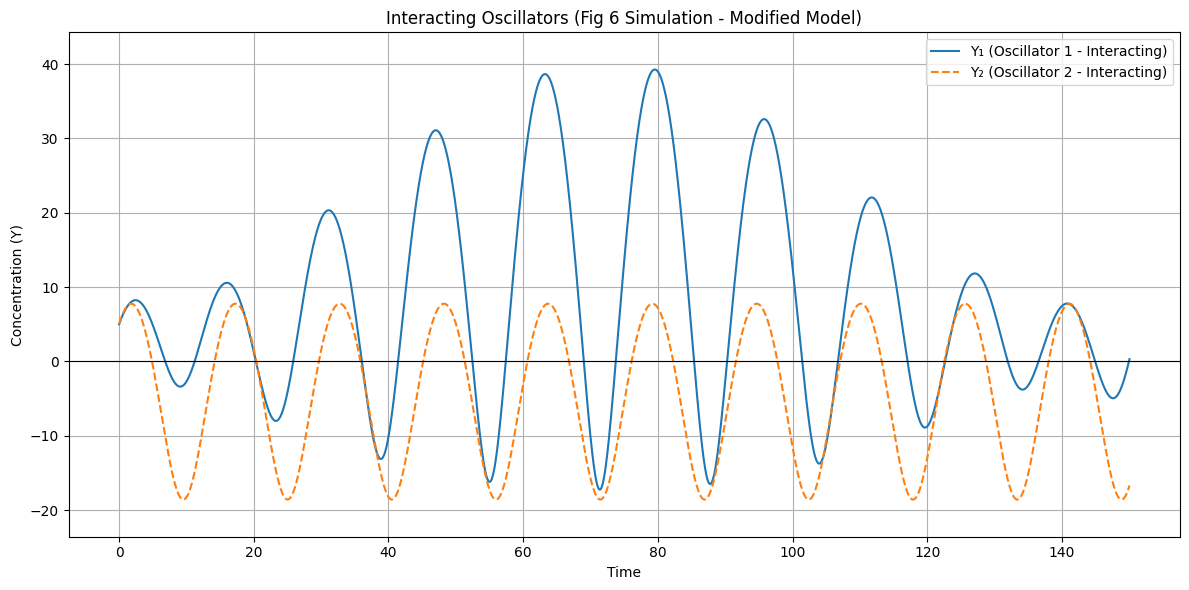

In [ ]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# --- Model Definition (Interacting Oscillators, Modified Eq) ---
def interacting_modified_oscillators(t, S_comb, p1, p2, k_int):
    """
    Simulates two INTERACTING oscillators using the modified Goodwin model.
    dX1/dt = a1 / (A1 + k11*Y1 + k12*Y2) - b1
    dY1/dt = alpha1*X1 - beta1*Y1
    dX2/dt = a2 / (A2 + k21*Y1 + k22*Y2) - b2
    dY2/dt = alpha2*X2 - beta2*Y2

    S_comb = [X1, Y1, X2, Y2]
    p1 = parameters for oscillator 1 (a1, A1, k11, b1, alpha1, beta1)
    p2 = parameters for oscillator 2 (a2, A2, k22, b2, alpha2, beta2)
    k_int = interaction parameters (k12, k21)
    """
    X1, Y1, X2, Y2 = S_comb
    k12, k21 = k_int['k12'], k_int['k21']

    # Oscillator 1 calculations
    denom1 = p1['A'] + p1['k'] * Y1 + k12 * Y2 # Interaction term k12*Y2 added
    epsilon = 1e-9
    if denom1 <= epsilon: denom1 = epsilon
    dX1_dt = p1['a'] / denom1 - p1['b']
    dY1_dt = p1['alpha'] * X1 - p1['beta']

    # Oscillator 2 calculations
    denom2 = p2['A'] + p2['k'] * Y2 + k21 * Y1 # Interaction term k21*Y1 added
    if denom2 <= epsilon: denom2 = epsilon
    dX2_dt = p2['a'] / denom2 - p2['b']
    dY2_dt = p2['alpha'] * X2 - p2['beta']

    return [dX1_dt, dY1_dt, dX2_dt, dY2_dt]


# --- Parameters for Figure 6 (Modified Model) ---
# Base parameters (same as Fig 5, using 'k' for k_self i.e. k11/k22)
params_mod_osc1_fig6 = {
    'a': 360.0, 'A': 36.0, 'k': 1.0, 'b': 10.0, 'alpha': 0.5, 'beta': 0.0
}
params_mod_osc2_fig6 = {
    'a': 360.0, 'A': 43.0, 'k': 1.0, 'b': 10.0, 'alpha': 0.6, 'beta': 0.0
}
# Interaction parameters for Fig 6
interaction_params_fig6 = {'k12': 0.3, 'k21': 0.0}


# --- Simulation ---
# Initial conditions (can use the same as before)
S0_comb_fig6 = [5, 5, 5, 5] # Initial state [X1, Y1, X2, Y2]

# Time span (might need longer to clearly see entrainment)
t_max_fig6 = 150
t_span_fig6 = (0, t_max_fig6)
t_eval_fig6 = np.linspace(t_span_fig6[0], t_span_fig6[1], 2000)

# Solve the combined ODE system
sol_combined_fig6 = solve_ivp(
    interacting_modified_oscillators,
    t_span_fig6,
    S0_comb_fig6,
    args=(params_mod_osc1_fig6, params_mod_osc2_fig6, interaction_params_fig6),
    dense_output=True,
    t_eval=t_eval_fig6,
    method='RK45',
    atol=1e-8, rtol=1e-8
)

# Check solver status
print(f"Solver status: {sol_combined_fig6.status}")
if sol_combined_fig6.status != 0:
    print(f"Solver message: {sol_combined_fig6.message}")

# Extract results
t_fig6 = sol_combined_fig6.t
X1_fig6, Y1_fig6, X2_fig6, Y2_fig6 = sol_combined_fig6.y

# --- Plotting (Y variables, similar to Fig 6) ---
plt.figure(figsize=(12, 6))
plt.plot(t_fig6, Y1_fig6, label='Y₁ (Oscillator 1 - Interacting)')
plt.plot(t_fig6, Y2_fig6, label='Y₂ (Oscillator 2 - Interacting)', linestyle='--')
plt.grid(True)
plt.xlabel("Time")
plt.ylabel("Concentration (Y)")
plt.title("Interacting Oscillators (Fig 6 Simulation - Modified Model)")
plt.legend()
# Adjust Y limits based on results
min_y_fig6 = min(np.min(Y1_fig6), np.min(Y2_fig6)) - 5
max_y_fig6 = max(np.max(Y1_fig6), np.max(Y2_fig6)) + 5
plt.ylim(min_y_fig6, max_y_fig6)
plt.axhline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

Solver status: 0
Peaks found in entrainment region for Y1 at t=[ 79.51987997  95.79894974 111.70292573 127.00675169 140.7351838
 154.98874719 170.51762941 186.57164291 202.85071268 219.2048012 ]
Peaks found in entrainment region for Y2 at t=[ 79.1447862   94.67366842 110.12753188 125.58139535 141.11027757
 156.56414104 172.0180045  187.54688672 203.00075019 218.45461365]


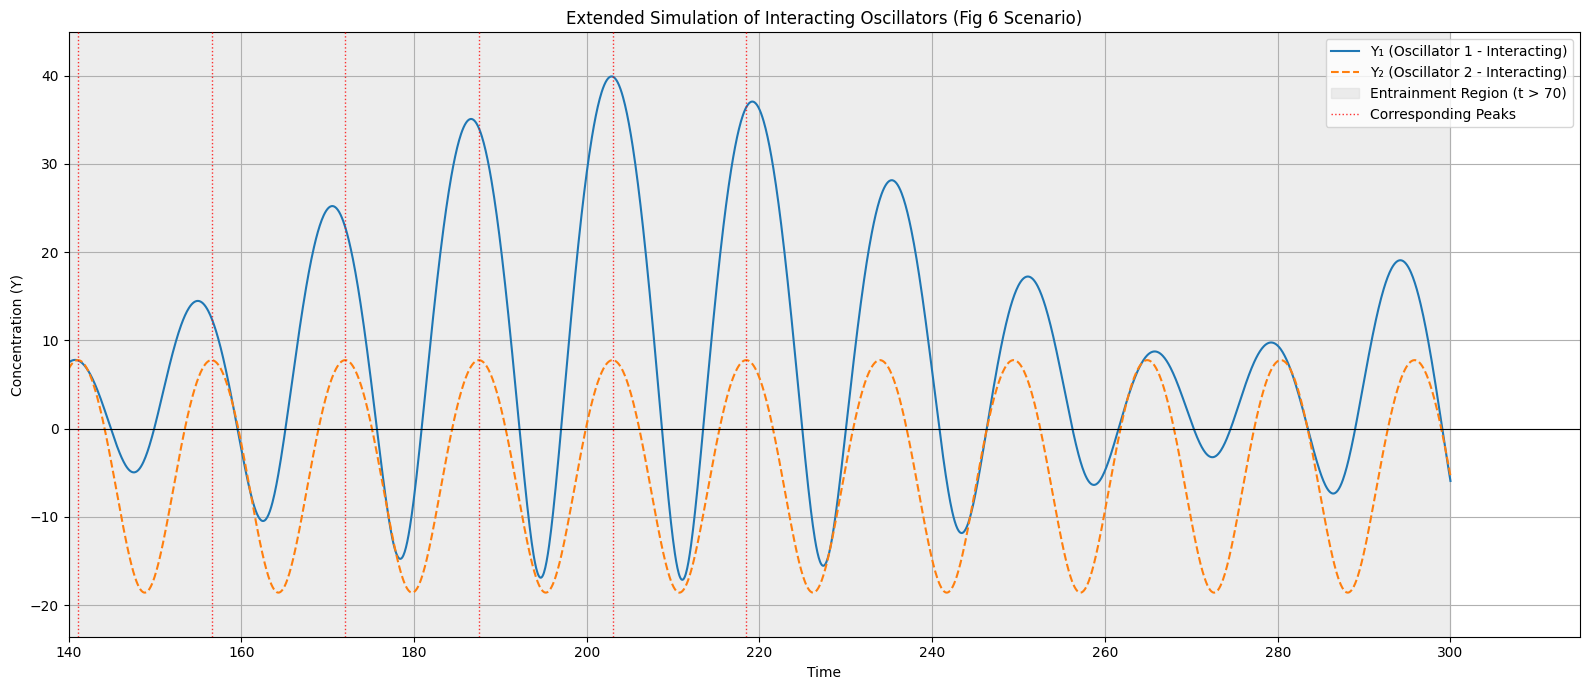

In [ ]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
from scipy.signal import find_peaks # Import find_peaks

# --- Model Definition (Interacting Oscillators, Modified Eq) ---
# Function 'interacting_modified_oscillators' remains the same as before
def interacting_modified_oscillators(t, S_comb, p1, p2, k_int):
    X1, Y1, X2, Y2 = S_comb
    k12, k21 = k_int['k12'], k_int['k21']
    epsilon = 1e-9 # Small number to prevent division by zero

    # Oscillator 1
    denom1 = p1['A'] + p1['k'] * Y1 + k12 * Y2
    if denom1 <= epsilon: denom1 = epsilon
    dX1_dt = p1['a'] / denom1 - p1['b']
    dY1_dt = p1['alpha'] * X1 - p1['beta']

    # Oscillator 2
    denom2 = p2['A'] + p2['k'] * Y2 + k21 * Y1
    if denom2 <= epsilon: denom2 = epsilon
    dX2_dt = p2['a'] / denom2 - p2['b']
    dY2_dt = p2['alpha'] * X2 - p2['beta']

    return [dX1_dt, dY1_dt, dX2_dt, dY2_dt]

# --- Parameters for Figure 6 (Modified Model) ---
# Base parameters
params_mod_osc1_fig6 = {
    'a': 360.0, 'A': 36.0, 'k': 1.0, 'b': 10.0, 'alpha': 0.5, 'beta': 0.0
}
params_mod_osc2_fig6 = {
    'a': 360.0, 'A': 43.0, 'k': 1.0, 'b': 10.0, 'alpha': 0.6, 'beta': 0.0
}
# Interaction parameters
interaction_params_fig6 = {'k12': 0.3, 'k21': 0.0}

# --- Simulation ---
# Initial conditions
S0_comb_fig6 = [5, 5, 5, 5]

# --- Extend Simulation Time ---
t_max_extended = 300 # Extend significantly further, e.g., to t=300
t_span_extended = (0, t_max_extended)
# More evaluation points for the longer duration
t_eval_extended = np.linspace(t_span_extended[0], t_span_extended[1], 4000)

# Solve the combined ODE system for the extended time
sol_combined_extended = solve_ivp(
    interacting_modified_oscillators,
    t_span_extended,
    S0_comb_fig6,
    args=(params_mod_osc1_fig6, params_mod_osc2_fig6, interaction_params_fig6),
    dense_output=True,
    t_eval=t_eval_extended,
    method='RK45',
    atol=1e-8, rtol=1e-8
)

# Check solver status
print(f"Solver status: {sol_combined_extended.status}")
if sol_combined_extended.status != 0:
    print(f"Solver message: {sol_combined_extended.message}")

# Extract results for the extended time
t_ext = sol_combined_extended.t
X1_ext, Y1_ext, X2_ext, Y2_ext = sol_combined_extended.y

# --- Enhanced Plotting for Extended Figure 6 Simulation ---
plt.figure(figsize=(16, 7)) # Make figure wider for longer time axis

# Plot the main data
plt.plot(t_ext, Y1_ext, label='Y₁ (Oscillator 1 - Interacting)', zorder=2)
plt.plot(t_ext, Y2_ext, label='Y₂ (Oscillator 2 - Interacting)', linestyle='--', zorder=2)

# --- Highlight Entrainment Region ---
# Keep the start time the same, entrainment should persist
entrainment_start_time = 70
plt.axvspan(entrainment_start_time, t_ext[-1], color='lightgrey', alpha=0.4,
            label=f'Entrainment Region (t > {entrainment_start_time})', zorder=1)

# --- Optional: Add vertical lines at corresponding peaks in the entrained region ---
# Find peaks *after* the entrainment start time in the extended data
peaks1_idx_ext, _ = find_peaks(Y1_ext[t_ext >= entrainment_start_time])
peaks2_idx_ext, _ = find_peaks(Y2_ext[t_ext >= entrainment_start_time])

# Get the actual time points corresponding to these indices
time_offset_idx_ext = np.where(t_ext >= entrainment_start_time)[0][0]
t_peaks1_ext = t_ext[peaks1_idx_ext + time_offset_idx_ext]
t_peaks2_ext = t_ext[peaks2_idx_ext + time_offset_idx_ext]

# Plot lines for several corresponding peaks across the extended range
num_peaks_to_show = 10 # Show more peaks over the longer time
if len(t_peaks1_ext) > 0 and len(t_peaks2_ext) > 0:
    print(f"Peaks found in entrainment region for Y1 at t={t_peaks1_ext[:num_peaks_to_show]}")
    print(f"Peaks found in entrainment region for Y2 at t={t_peaks2_ext[:num_peaks_to_show]}")
    min_len = min(len(t_peaks1_ext), len(t_peaks2_ext), num_peaks_to_show)
    for i in range(min_len):
        peak_time = t_peaks2_ext[i] # Use the faster oscillator's peak time
        plt.axvline(peak_time, color='red', linestyle=':', linewidth=1, alpha=0.8, zorder=3)
        if i == 0:
           plt.axvline(peak_time, color='red', linestyle=':', linewidth=1, alpha=0.8, zorder=3, label='Corresponding Peaks')

# --- Standard Plotting Elements ---
plt.grid(True)
plt.xlabel("Time")
plt.ylabel("Concentration (Y)")
plt.title("Extended Simulation of Interacting Oscillators (Fig 6 Scenario)")
plt.legend(loc='upper right')

# Adjust Y limits based on results
min_y_ext = min(np.min(Y1_ext), np.min(Y2_ext)) - 5
max_y_ext = max(np.max(Y1_ext), np.max(Y2_ext)) + 5
plt.ylim(min_y_ext, max_y_ext)
plt.axhline(0, color='black', linewidth=0.8, zorder=2)

# --- Focus the view on the later part, starting from t=140 ---
plt.xlim(left=140) # Set the minimum x-axis value to 140

plt.tight_layout()
plt.show()

Solver status: 0


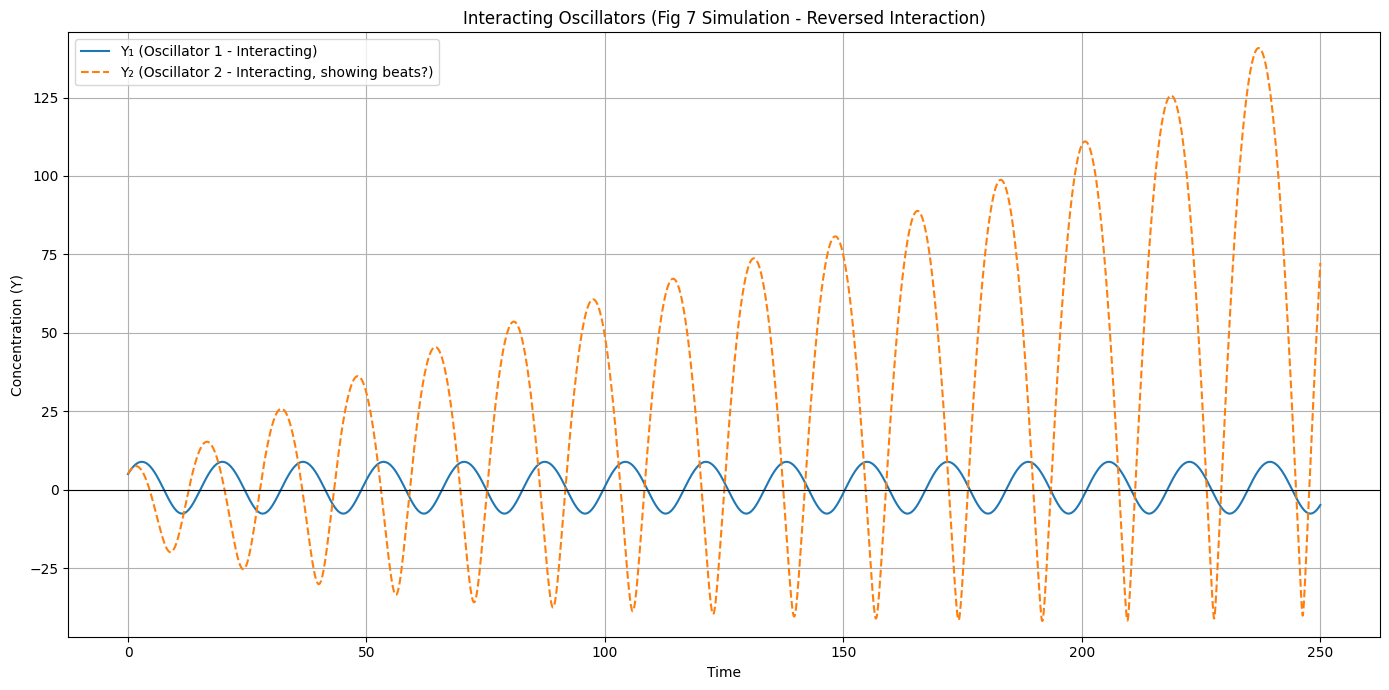

In [ ]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# --- Model Definition (Interacting Oscillators, Modified Eq) ---
# Function 'interacting_modified_oscillators' remains the same as before
def interacting_modified_oscillators(t, S_comb, p1, p2, k_int):
    X1, Y1, X2, Y2 = S_comb
    k12, k21 = k_int['k12'], k_int['k21']
    epsilon = 1e-9 # Small number to prevent division by zero

    # Oscillator 1
    denom1 = p1['A'] + p1['k'] * Y1 + k12 * Y2
    if denom1 <= epsilon: denom1 = epsilon
    dX1_dt = p1['a'] / denom1 - p1['b']
    dY1_dt = p1['alpha'] * X1 - p1['beta']

    # Oscillator 2
    denom2 = p2['A'] + p2['k'] * Y2 + k21 * Y1 # k21 is now non-zero
    if denom2 <= epsilon: denom2 = epsilon
    dX2_dt = p2['a'] / denom2 - p2['b']
    dY2_dt = p2['alpha'] * X2 - p2['beta']

    return [dX1_dt, dY1_dt, dX2_dt, dY2_dt]

# --- Parameters for Figure 7 (Modified Model) ---
# Base parameters (same as Fig 5/6)
params_mod_osc1_fig7 = {
    'a': 360.0, 'A': 36.0, 'k': 1.0, 'b': 10.0, 'alpha': 0.5, 'beta': 0.0
}
params_mod_osc2_fig7 = {
    'a': 360.0, 'A': 43.0, 'k': 1.0, 'b': 10.0, 'alpha': 0.6, 'beta': 0.0
}
# Interaction parameters for Fig 7 (Reversed interaction)
interaction_params_fig7 = {'k12': 0.0, 'k21': 0.3}


# --- Simulation ---
# Initial conditions (can use the same as before)
S0_comb_fig7 = [5, 5, 5, 5] # Initial state [X1, Y1, X2, Y2]

# Time span (Need sufficient time to observe beats - paper used 2 sec vs 1 sec)
# Let's try longer than Fig 6 initial run.
t_max_fig7 = 250
t_span_fig7 = (0, t_max_fig7)
t_eval_fig7 = np.linspace(t_span_fig7[0], t_span_fig7[1], 3500) # More points

# Solve the combined ODE system
sol_combined_fig7 = solve_ivp(
    interacting_modified_oscillators,
    t_span_fig7,
    S0_comb_fig7,
    args=(params_mod_osc1_fig7, params_mod_osc2_fig7, interaction_params_fig7),
    dense_output=True,
    t_eval=t_eval_fig7,
    method='RK45',
    atol=1e-8, rtol=1e-8
)

# Check solver status
print(f"Solver status: {sol_combined_fig7.status}")
if sol_combined_fig7.status != 0:
    print(f"Solver message: {sol_combined_fig7.message}")

# Extract results
t_fig7 = sol_combined_fig7.t
X1_fig7, Y1_fig7, X2_fig7, Y2_fig7 = sol_combined_fig7.y

# --- Plotting (Y variables, similar to Fig 7) ---
plt.figure(figsize=(14, 7)) # Wider plot maybe helpful
plt.plot(t_fig7, Y1_fig7, label='Y₁ (Oscillator 1 - Interacting)')
plt.plot(t_fig7, Y2_fig7, label='Y₂ (Oscillator 2 - Interacting, showing beats?)', linestyle='--')
plt.grid(True)
plt.xlabel("Time")
plt.ylabel("Concentration (Y)")
plt.title("Interacting Oscillators (Fig 7 Simulation - Reversed Interaction)")
plt.legend()
# Adjust Y limits based on results
min_y_fig7 = min(np.min(Y1_fig7), np.min(Y2_fig7)) - 5
max_y_fig7 = max(np.max(Y1_fig7), np.max(Y2_fig7)) + 5
plt.ylim(min_y_fig7, max_y_fig7)
plt.axhline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

Solver status: 0


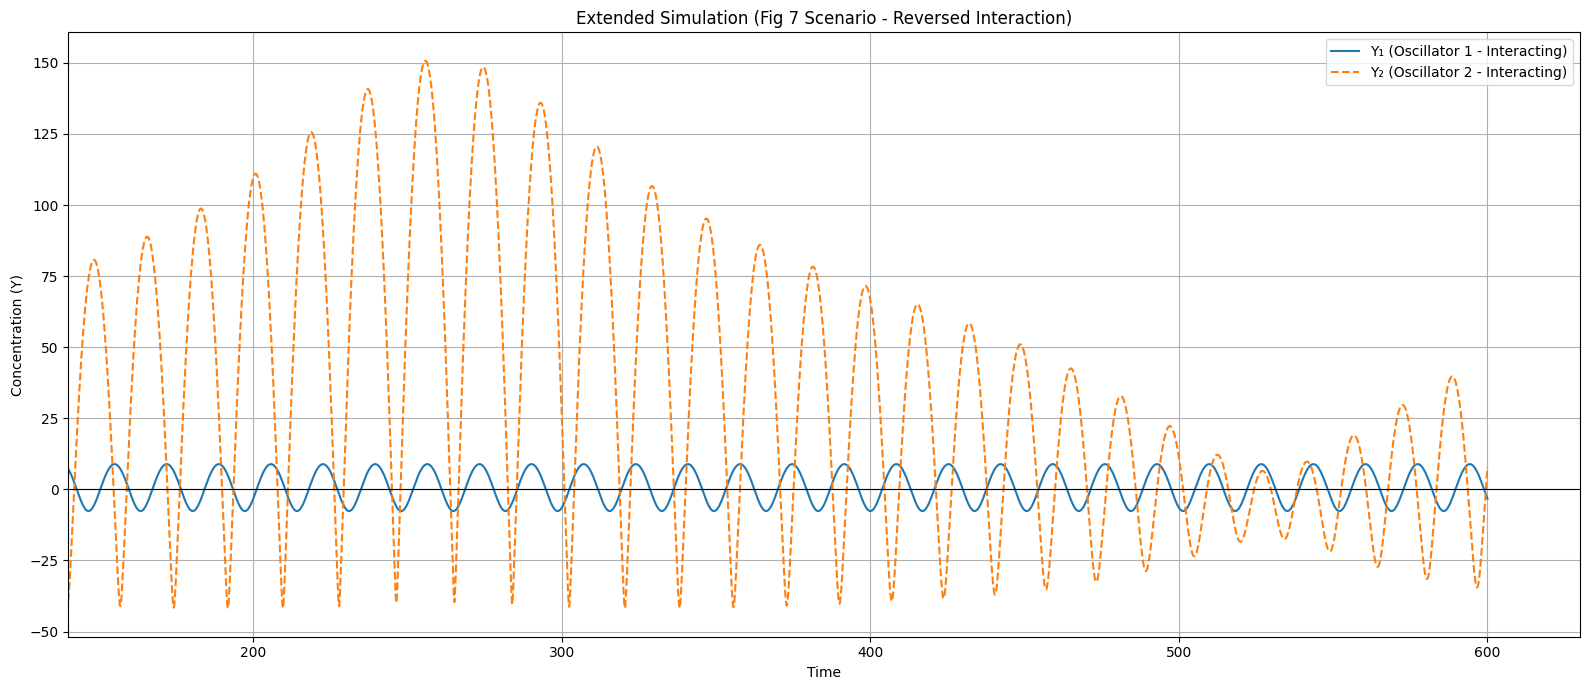

In [ ]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# --- Model Definition (Interacting Oscillators, Modified Eq) ---
# Function 'interacting_modified_oscillators' remains the same
def interacting_modified_oscillators(t, S_comb, p1, p2, k_int):
    X1, Y1, X2, Y2 = S_comb
    k12, k21 = k_int['k12'], k_int['k21']
    epsilon = 1e-9 # Small number to prevent division by zero

    # Oscillator 1
    denom1 = p1['A'] + p1['k'] * Y1 + k12 * Y2
    if denom1 <= epsilon: denom1 = epsilon
    dX1_dt = p1['a'] / denom1 - p1['b']
    dY1_dt = p1['alpha'] * X1 - p1['beta']

    # Oscillator 2
    denom2 = p2['A'] + p2['k'] * Y2 + k21 * Y1 # k21 is non-zero
    if denom2 <= epsilon: denom2 = epsilon
    dX2_dt = p2['a'] / denom2 - p2['b']
    dY2_dt = p2['alpha'] * X2 - p2['beta']

    return [dX1_dt, dY1_dt, dX2_dt, dY2_dt]


# --- Parameters for Figure 7 (Modified Model) ---
params_mod_osc1_fig7 = {
    'a': 360.0, 'A': 36.0, 'k': 1.0, 'b': 10.0, 'alpha': 0.5, 'beta': 0.0
}
params_mod_osc2_fig7 = {
    'a': 360.0, 'A': 43.0, 'k': 1.0, 'b': 10.0, 'alpha': 0.6, 'beta': 0.0
}
interaction_params_fig7 = {'k12': 0.0, 'k21': 0.3}


# --- Simulation ---
# Initial conditions
S0_comb_fig7 = [5, 5, 5, 5]

# --- Extend Simulation Time Significantly ---
t_max_very_long = 600 # Extend much further, e.g., to t=600
t_span_very_long = (0, t_max_very_long)
# More evaluation points
t_eval_very_long = np.linspace(t_span_very_long[0], t_span_very_long[1], 6000)

# Solve the combined ODE system for the very long time
sol_combined_vlong_fig7 = solve_ivp(
    interacting_modified_oscillators,
    t_span_very_long,
    S0_comb_fig7,
    args=(params_mod_osc1_fig7, params_mod_osc2_fig7, interaction_params_fig7),
    dense_output=True,
    t_eval=t_eval_very_long,
    method='RK45',
    atol=1e-8, rtol=1e-8
)

# Check solver status
print(f"Solver status: {sol_combined_vlong_fig7.status}")
if sol_combined_vlong_fig7.status != 0:
    print(f"Solver message: {sol_combined_vlong_fig7.message}")

# Extract results
t_vlong = sol_combined_vlong_fig7.t
X1_vlong, Y1_vlong, X2_vlong, Y2_vlong = sol_combined_vlong_fig7.y

# --- Plotting (Focus on later time, e.g., t > 140) ---
plt.figure(figsize=(16, 7)) # Wider plot

plt.plot(t_vlong, Y1_vlong, label='Y₁ (Oscillator 1 - Interacting)')
plt.plot(t_vlong, Y2_vlong, label='Y₂ (Oscillator 2 - Interacting)', linestyle='--')

plt.grid(True)
plt.xlabel("Time")
plt.ylabel("Concentration (Y)")
plt.title("Extended Simulation (Fig 7 Scenario - Reversed Interaction)")
plt.legend()

# Adjust Y limits dynamically based on the later part of the simulation
later_time_idx = t_vlong > 140
min_y_later = min(np.min(Y1_vlong[later_time_idx]), np.min(Y2_vlong[later_time_idx])) - 10
max_y_later = max(np.max(Y1_vlong[later_time_idx]), np.max(Y2_vlong[later_time_idx])) + 10
plt.ylim(min_y_later, max_y_later) # Set Y limits based on later data

plt.axhline(0, color='black', linewidth=0.8)

# --- Focus the view on the later part ---
plt.xlim(left=140) # Start viewing from t=140

plt.tight_layout()
plt.show()

Solver status: 0


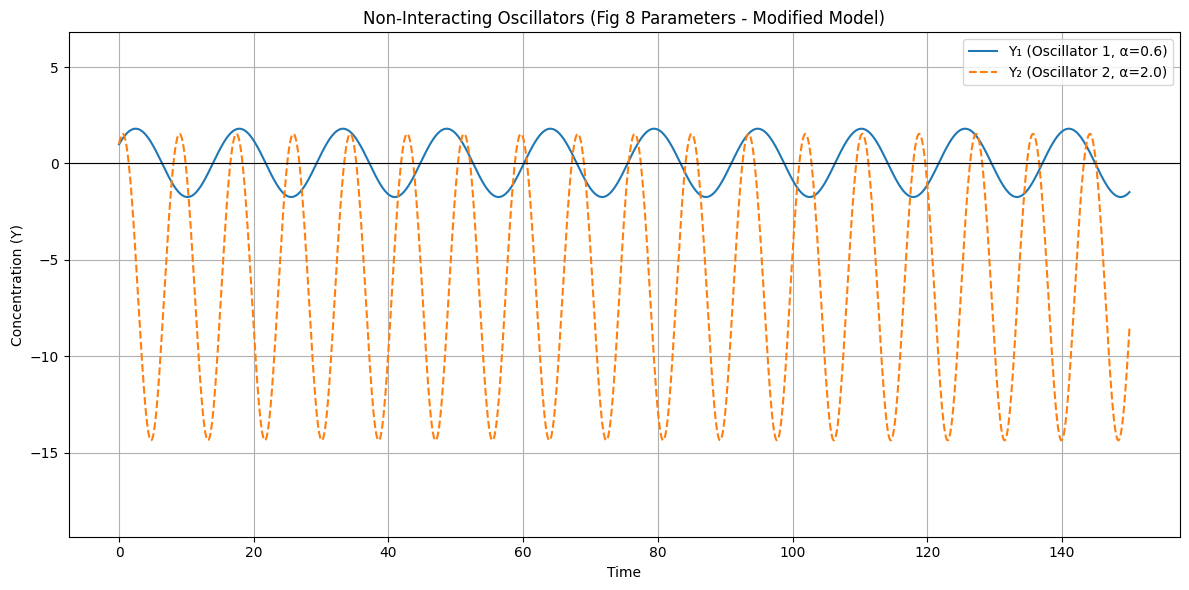

In [ ]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# --- Model Definition (Using YOUR working version for Fig 2/3) ---
# Function 'modified_goodwin_oscillator' remains the same
def modified_goodwin_oscillator(t, state, params):
    X, Y = state
    a, A, k, b, alpha, beta = params['a'], params['A'], params['k'], params['b'], params['alpha'], params['beta']
    denominator = A + k * Y
    epsilon = 1e-9
    if denominator <= epsilon: denominator = epsilon
    dXdt = a / denominator - b
    dYdt = alpha * X - beta # Note: beta is 0 for this figure
    return [dXdt, dYdt]

# Function 'two_independent_modified_oscillators' remains the same
def two_independent_modified_oscillators(t, S_comb, p1, p2):
    X1, Y1, X2, Y2 = S_comb
    dX1_dt, dY1_dt = modified_goodwin_oscillator(t, [X1, Y1], p1)
    dX2_dt, dY2_dt = modified_goodwin_oscillator(t, [X2, Y2], p2)
    return [dX1_dt, dY1_dt, dX2_dt, dY2_dt]

# --- Parameters for Figure 8 (Modified Model) ---
# Base parameters unchanged, alpha values are new
params_mod_osc1_fig8 = {
    'a': 360.0, 'A': 36.0, 'k': 1.0, 'b': 10.0,
    'alpha': 0.6,  # New alpha1
    'beta': 0.0
}
params_mod_osc2_fig8 = {
    'a': 360.0, 'A': 43.0, 'k': 1.0, 'b': 10.0,
    'alpha': 2.0,  # New alpha2
    'beta': 0.0
}

# --- Simulation ---
# Initial conditions
S0_comb_fig8 = [1, 1, 1, 1] # Start near origin, adjusted based on expected SS

# Time span
t_max_fig8 = 150 # Let's use a bit longer time to see cycles clearly
t_span_fig8 = (0, t_max_fig8)
t_eval_fig8 = np.linspace(t_span_fig8[0], t_span_fig8[1], 2000)

# Solve the combined ODE system
sol_combined_fig8 = solve_ivp(
    two_independent_modified_oscillators,
    t_span_fig8,
    S0_comb_fig8,
    args=(params_mod_osc1_fig8, params_mod_osc2_fig8),
    dense_output=True,
    t_eval=t_eval_fig8,
    method='RK45',
    atol=1e-8, rtol=1e-8
)

# Check solver status
print(f"Solver status: {sol_combined_fig8.status}")
if sol_combined_fig8.status != 0:
    print(f"Solver message: {sol_combined_fig8.message}")

# Extract results
t_fig8 = sol_combined_fig8.t
X1_fig8, Y1_fig8, X2_fig8, Y2_fig8 = sol_combined_fig8.y

# --- Plotting (Y variables, similar to Fig 8) ---
plt.figure(figsize=(12, 6))
plt.plot(t_fig8, Y1_fig8, label='Y₁ (Oscillator 1, α=0.6)')
plt.plot(t_fig8, Y2_fig8, label='Y₂ (Oscillator 2, α=2.0)', linestyle='--')
plt.grid(True)
plt.xlabel("Time")
plt.ylabel("Concentration (Y)")
plt.title("Non-Interacting Oscillators (Fig 8 Parameters - Modified Model)")
plt.legend()
# Adjust Y limits based on results
min_y_fig8 = min(np.min(Y1_fig8), np.min(Y2_fig8)) - 5
max_y_fig8 = max(np.max(Y1_fig8), np.max(Y2_fig8)) + 5
plt.ylim(min_y_fig8, max_y_fig8)
plt.axhline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

Solver status: 0


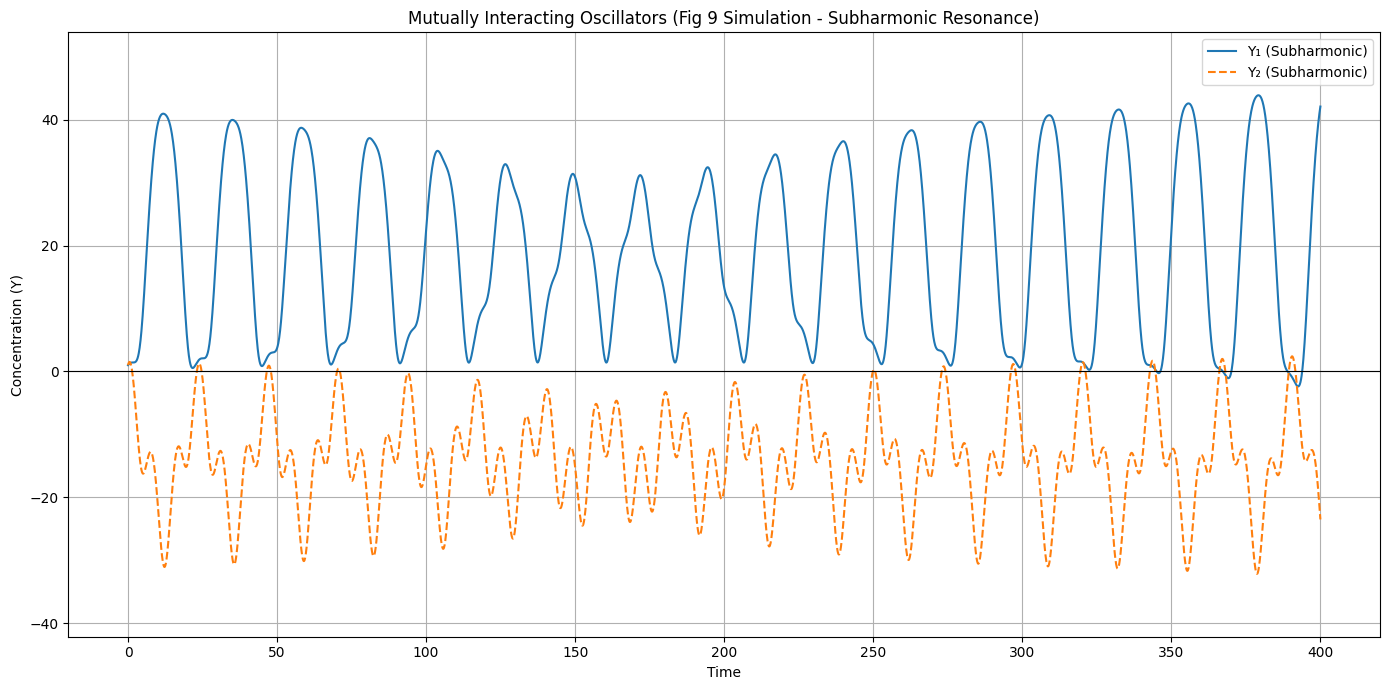

In [ ]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# --- Model Definition (Interacting Oscillators, Modified Eq) ---
# Function 'interacting_modified_oscillators' remains the same
def interacting_modified_oscillators(t, S_comb, p1, p2, k_int):
    X1, Y1, X2, Y2 = S_comb
    k12, k21 = k_int['k12'], k_int['k21']
    epsilon = 1e-9 # Small number to prevent division by zero

    # Oscillator 1
    denom1 = p1['A'] + p1['k'] * Y1 + k12 * Y2 # k12 is now non-zero
    if denom1 <= epsilon: denom1 = epsilon
    dX1_dt = p1['a'] / denom1 - p1['b']
    dY1_dt = p1['alpha'] * X1 - p1['beta']

    # Oscillator 2
    denom2 = p2['A'] + p2['k'] * Y2 + k21 * Y1 # k21 is now non-zero
    if denom2 <= epsilon: denom2 = epsilon
    dX2_dt = p2['a'] / denom2 - p2['b']
    dY2_dt = p2['alpha'] * X2 - p2['beta']

    return [dX1_dt, dY1_dt, dX2_dt, dY2_dt]

# --- Parameters for Figure 9 (Modified Model) ---
# Base parameters from Fig 8
params_mod_osc1_fig9 = {
    'a': 360.0, 'A': 36.0, 'k': 1.0, 'b': 10.0, 'alpha': 0.6, 'beta': 0.0
}
params_mod_osc2_fig9 = {
    'a': 360.0, 'A': 43.0, 'k': 1.0, 'b': 10.0, 'alpha': 2.0, 'beta': 0.0
}
# Interaction parameters for Fig 9 (Mutual, strong)
interaction_params_fig9 = {'k12': 1.2, 'k21': 0.4}

# --- Simulation ---
# Initial conditions
S0_comb_fig9 = [1, 1, 1, 1] # Start near origin

# Time span (Needs to be long enough to see the low-frequency oscillation)
t_max_fig9 = 400 # Increase time significantly
t_span_fig9 = (0, t_max_fig9)
t_eval_fig9 = np.linspace(t_span_fig9[0], t_span_fig9[1], 4000) # More points

# Solve the combined ODE system
sol_combined_fig9 = solve_ivp(
    interacting_modified_oscillators,
    t_span_fig9,
    S0_comb_fig9,
    args=(params_mod_osc1_fig9, params_mod_osc2_fig9, interaction_params_fig9),
    dense_output=True,
    t_eval=t_eval_fig9,
    method='RK45',
    atol=1e-8, rtol=1e-8
)

# Check solver status
print(f"Solver status: {sol_combined_fig9.status}")
if sol_combined_fig9.status != 0:
    print(f"Solver message: {sol_combined_fig9.message}")

# Extract results
t_fig9 = sol_combined_fig9.t
X1_fig9, Y1_fig9, X2_fig9, Y2_fig9 = sol_combined_fig9.y

# --- Plotting (Y variables, similar to Fig 9) ---
plt.figure(figsize=(14, 7))
plt.plot(t_fig9, Y1_fig9, label='Y₁ (Subharmonic)')
plt.plot(t_fig9, Y2_fig9, label='Y₂ (Subharmonic)', linestyle='--')
plt.grid(True)
plt.xlabel("Time")
plt.ylabel("Concentration (Y)")
plt.title("Mutually Interacting Oscillators (Fig 9 Simulation - Subharmonic Resonance)")
plt.legend()
# Adjust Y limits - expect larger amplitudes
min_y_fig9 = min(np.min(Y1_fig9), np.min(Y2_fig9)) - 10 # Allow more space
max_y_fig9 = max(np.max(Y1_fig9), np.max(Y2_fig9)) + 10
plt.ylim(min_y_fig9, max_y_fig9)
plt.axhline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

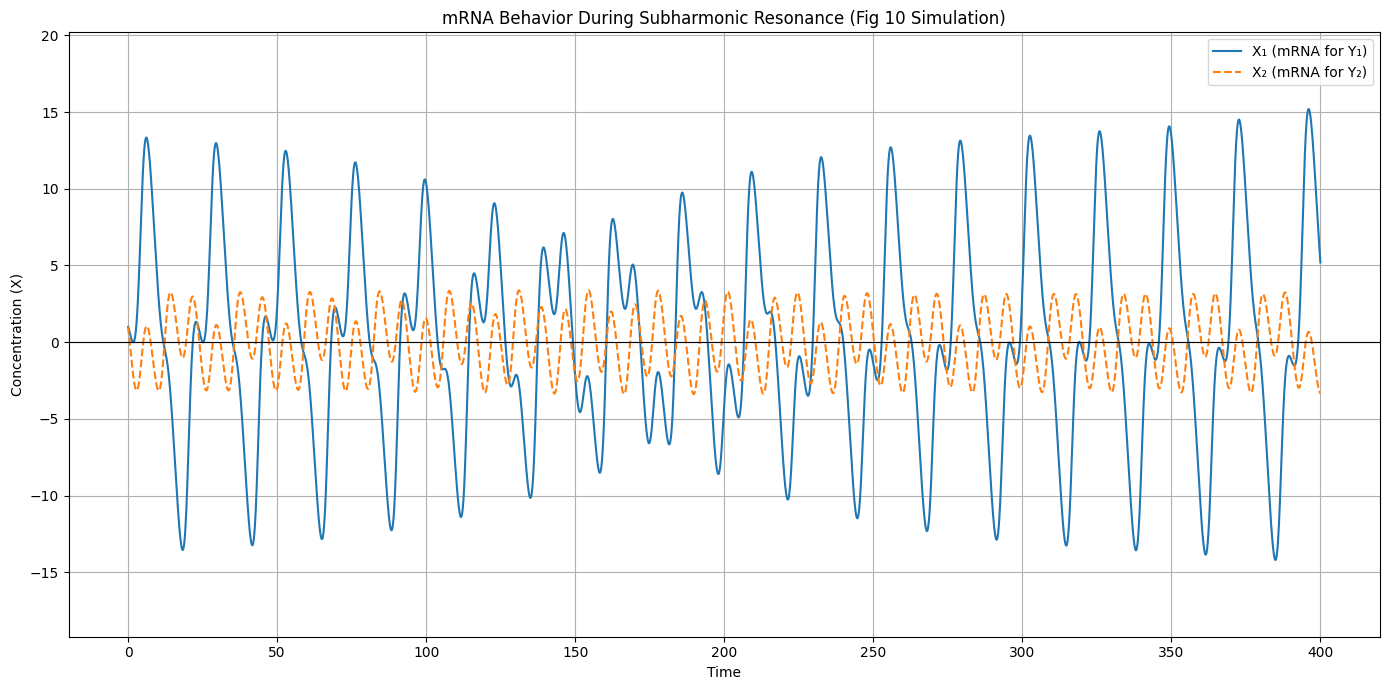

In [ ]:
import numpy as np
# solve_ivp and plt are assumed to be imported
# Results from the Figure 9 simulation are assumed to be available:
# t_fig9, X1_fig9, Y1_fig9, X2_fig9, Y2_fig9

# --- Plotting X variables (Corresponding to Fig 10) ---
plt.figure(figsize=(14, 7)) # Match size of Fig 9 plot

# Plot X1 and X2
plt.plot(t_fig9, X1_fig9, label='X₁ (mRNA for Y₁)')
plt.plot(t_fig9, X2_fig9, label='X₂ (mRNA for Y₂)', linestyle='--') # Use different style for clarity

plt.grid(True)
plt.xlabel("Time")
plt.ylabel("Concentration (X)")
plt.title("mRNA Behavior During Subharmonic Resonance (Fig 10 Simulation)")
plt.legend()

# Adjust Y limits based on the range of X variables
# May need different limits than the Y plot
min_x_fig10 = min(np.min(X1_fig9), np.min(X2_fig9)) - 5 # Give some margin
max_x_fig10 = max(np.max(X1_fig9), np.max(X2_fig9)) + 5
plt.ylim(min_x_fig10, max_x_fig10)
plt.axhline(0, color='black', linewidth=0.8) # Add zero line

plt.tight_layout()
plt.show()

Solver status: 0


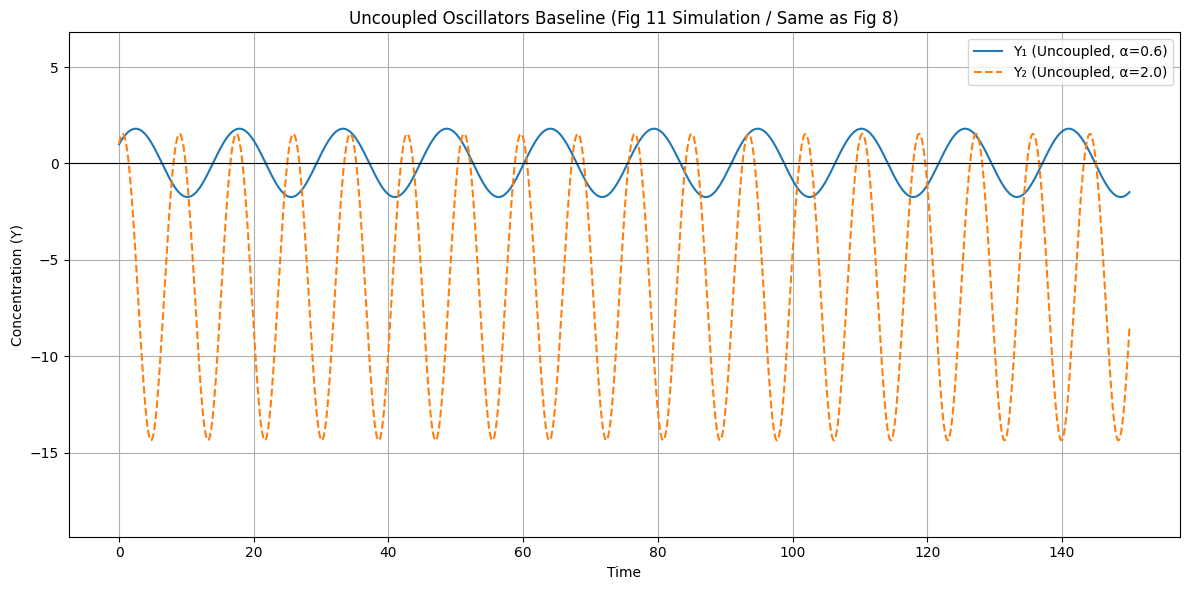

In [ ]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# --- Model Definition (Using YOUR working version for Fig 2/3) ---
# Function 'modified_goodwin_oscillator' remains the same
def modified_goodwin_oscillator(t, state, params):
    X, Y = state
    a, A, k, b, alpha, beta = params['a'], params['A'], params['k'], params['b'], params['alpha'], params['beta']
    denominator = A + k * Y
    epsilon = 1e-9
    if denominator <= epsilon: denominator = epsilon
    dXdt = a / denominator - b
    dYdt = alpha * X - beta
    return [dXdt, dYdt]

# Function 'two_independent_modified_oscillators' remains the same
def two_independent_modified_oscillators(t, S_comb, p1, p2):
    X1, Y1, X2, Y2 = S_comb
    dX1_dt, dY1_dt = modified_goodwin_oscillator(t, [X1, Y1], p1)
    dX2_dt, dY2_dt = modified_goodwin_oscillator(t, [X2, Y2], p2)
    return [dX1_dt, dY1_dt, dX2_dt, dY2_dt]

# --- Parameters for Figure 11 (Same as Fig 8) ---
params_mod_osc1_fig11 = { # Same as Fig 8
    'a': 360.0, 'A': 36.0, 'k': 1.0, 'b': 10.0, 'alpha': 0.6, 'beta': 0.0
}
params_mod_osc2_fig11 = { # Same as Fig 8
    'a': 360.0, 'A': 43.0, 'k': 1.0, 'b': 10.0, 'alpha': 2.0, 'beta': 0.0
}

# --- Simulation ---
# Initial conditions (can use same as Fig 8)
S0_comb_fig11 = [1, 1, 1, 1]

# Time span (Match Fig 8 or adjust based on paper's mention of "4 sec")
# Let's keep it similar to Fig 8 for direct comparison.
t_max_fig11 = 150
t_span_fig11 = (0, t_max_fig11)
t_eval_fig11 = np.linspace(t_span_fig11[0], t_span_fig11[1], 2000)

# Solve the combined ODE system
sol_combined_fig11 = solve_ivp(
    two_independent_modified_oscillators,
    t_span_fig11,
    S0_comb_fig11,
    args=(params_mod_osc1_fig11, params_mod_osc2_fig11),
    dense_output=True,
    t_eval=t_eval_fig11,
    method='RK45',
    atol=1e-8, rtol=1e-8
)

# Check solver status
print(f"Solver status: {sol_combined_fig11.status}")
if sol_combined_fig11.status != 0:
    print(f"Solver message: {sol_combined_fig11.message}")

# Extract results
t_fig11 = sol_combined_fig11.t
X1_fig11, Y1_fig11, X2_fig11, Y2_fig11 = sol_combined_fig11.y

# --- Plotting (Y variables, similar to Fig 11/Fig 8) ---
plt.figure(figsize=(12, 6))
plt.plot(t_fig11, Y1_fig11, label='Y₁ (Uncoupled, α=0.6)')
plt.plot(t_fig11, Y2_fig11, label='Y₂ (Uncoupled, α=2.0)', linestyle='--')
plt.grid(True)
plt.xlabel("Time")
plt.ylabel("Concentration (Y)")
plt.title("Uncoupled Oscillators Baseline (Fig 11 Simulation / Same as Fig 8)")
plt.legend()
# Use similar Y limits as Fig 8 plot for comparison
min_y_fig11 = min(np.min(Y1_fig11), np.min(Y2_fig11)) - 5
max_y_fig11 = max(np.max(Y1_fig11), np.max(Y2_fig11)) + 5
plt.ylim(min_y_fig11, max_y_fig11)
plt.axhline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

Solver status: 0


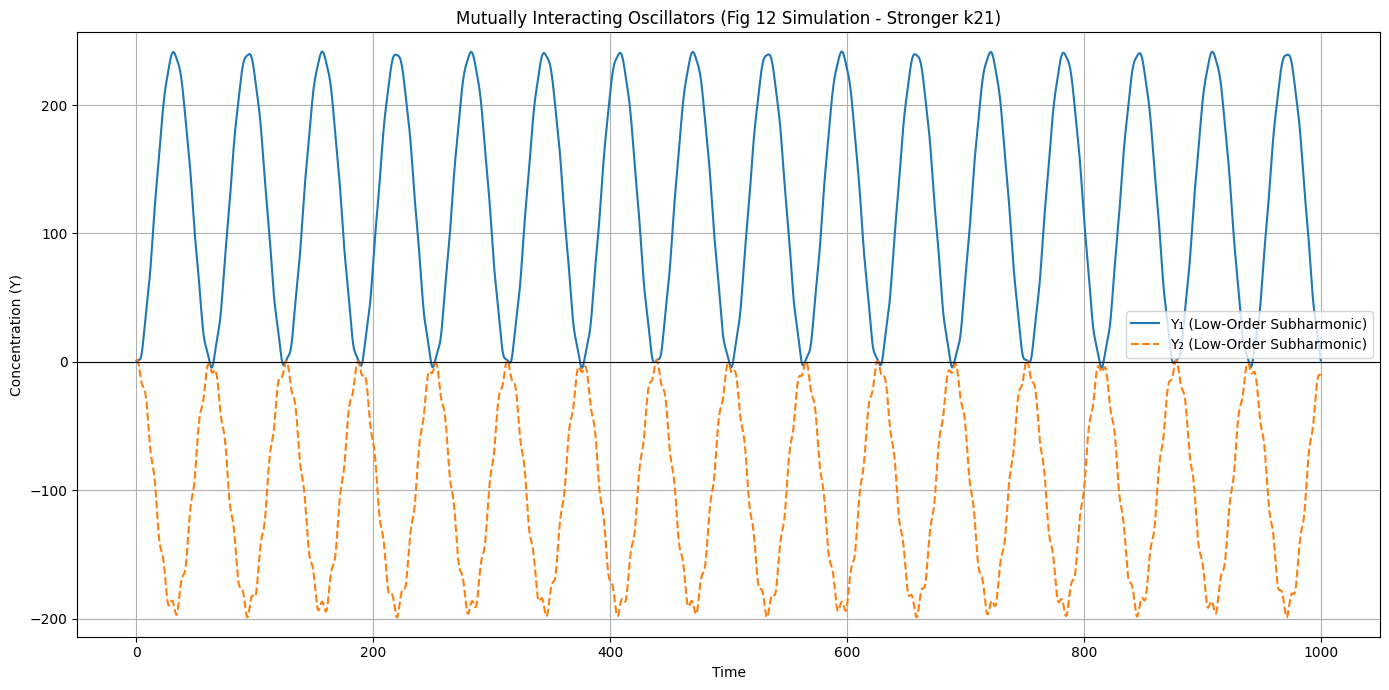

In [ ]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# --- Model Definition (Interacting Oscillators, Modified Eq) ---
# Function 'interacting_modified_oscillators' remains the same
def interacting_modified_oscillators(t, S_comb, p1, p2, k_int):
    X1, Y1, X2, Y2 = S_comb
    k12, k21 = k_int['k12'], k_int['k21']
    epsilon = 1e-9 # Small number to prevent division by zero

    # Oscillator 1
    denom1 = p1['A'] + p1['k'] * Y1 + k12 * Y2
    if denom1 <= epsilon: denom1 = epsilon
    dX1_dt = p1['a'] / denom1 - p1['b']
    dY1_dt = p1['alpha'] * X1 - p1['beta']

    # Oscillator 2
    denom2 = p2['A'] + p2['k'] * Y2 + k21 * Y1
    if denom2 <= epsilon: denom2 = epsilon
    dX2_dt = p2['a'] / denom2 - p2['b']
    dY2_dt = p2['alpha'] * X2 - p2['beta']

    return [dX1_dt, dY1_dt, dX2_dt, dY2_dt]

# --- Parameters for Figure 12 (Modified Model) ---
# Base parameters from Fig 8/11
params_mod_osc1_fig12 = {
    'a': 360.0, 'A': 36.0, 'k': 1.0, 'b': 10.0, 'alpha': 0.6, 'beta': 0.0
}
params_mod_osc2_fig12 = {
    'a': 360.0, 'A': 43.0, 'k': 1.0, 'b': 10.0, 'alpha': 2.0, 'beta': 0.0
}
# Interaction parameters for Fig 12 (New mutual, strong)
interaction_params_fig12 = {'k12': 1.2, 'k21': 0.77}

# --- Simulation ---
# Initial conditions
S0_comb_fig12 = [1, 1, 1, 1] # Start near origin

# Time span (Needs to be VERY long)
t_max_fig12 = 1000 # Significantly increase time
t_span_fig12 = (0, t_max_fig12)
t_eval_fig12 = np.linspace(t_span_fig12[0], t_span_fig12[1], 8000) # More points

# --- Run Simulation (Corrected solve_ivp call) ---
sol_combined_fig12 = solve_ivp(
    interacting_modified_oscillators, # The function defining the ODEs
    t_span_fig12,                     # Time interval [t_start, t_end]
    S0_comb_fig12,                    # Initial state vector [X1_0, Y1_0, X2_0, Y2_0]
    method='RK45',                    # Integration method (default is good)
    t_eval=t_eval_fig12,              # Times at which to store the computed solution
    dense_output=True,                # Compute a continuous solution
    args=(params_mod_osc1_fig12, params_mod_osc2_fig12, interaction_params_fig12), # Extra args to ODE func
    atol=1e-8, rtol=1e-8              # Absolute and relative tolerances
)                                     # <<< Ensure this closing parenthesis is present

# Check solver status
print(f"Solver status: {sol_combined_fig12.status}")
if sol_combined_fig12.status != 0:
    print(f"Solver message: {sol_combined_fig12.message}")

# Extract results
# Check if simulation was successful before trying to access results
if sol_combined_fig12.success:
    t_fig12 = sol_combined_fig12.t
    X1_fig12, Y1_fig12, X2_fig12, Y2_fig12 = sol_combined_fig12.y

    # --- Plotting (Y variables, similar to Fig 12) ---
    plt.figure(figsize=(14, 7))
    plt.plot(t_fig12, Y1_fig12, label='Y₁ (Low-Order Subharmonic)')
    plt.plot(t_fig12, Y2_fig12, label='Y₂ (Low-Order Subharmonic)', linestyle='--')
    plt.grid(True)
    plt.xlabel("Time")
    plt.ylabel("Concentration (Y)")
    plt.title("Mutually Interacting Oscillators (Fig 12 Simulation - Stronger k21)")
    plt.legend()
    # Adjust Y limits - expect potentially very large amplitudes
    min_y_fig12 = min(np.min(Y1_fig12), np.min(Y2_fig12)) - 15 # Allow more space
    max_y_fig12 = max(np.max(Y1_fig12), np.max(Y2_fig12)) + 15
    plt.ylim(min_y_fig12, max_y_fig12)
    plt.axhline(0, color='black', linewidth=0.8)
    plt.tight_layout()
    plt.show()
else:
    print("Simulation failed, cannot plot results.")

Running simulation for Figures 13, 14, 15...
Solver status: 0
Simulation successful. Preparing plots...

--- Generating Figure 13: Time Course ---
Displaying Figure 13. Please CLOSE this plot window to generate the next plot.


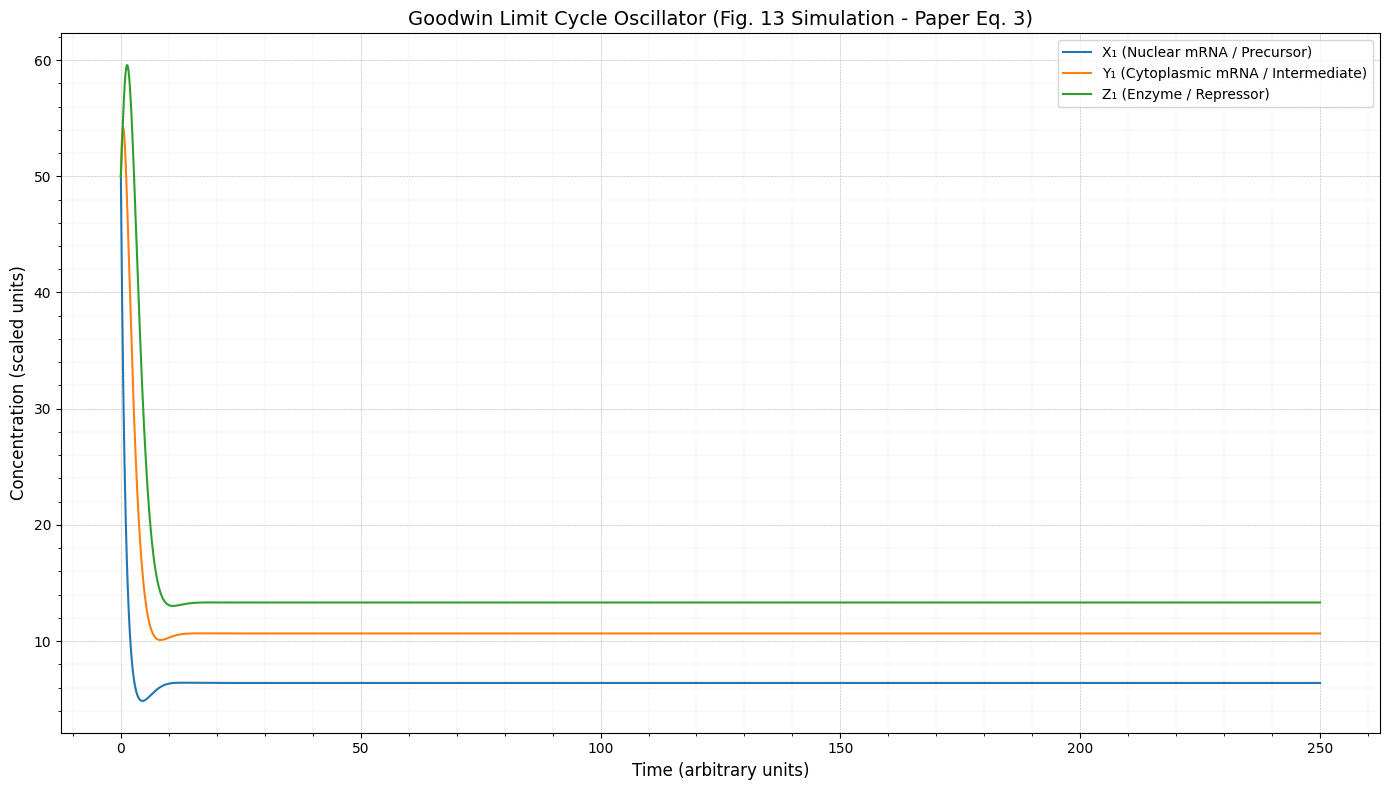


--- Generating Figure 14: Phase Portrait (Y vs Z) ---
Displaying Figure 14. Please CLOSE this plot window to generate the next plot.


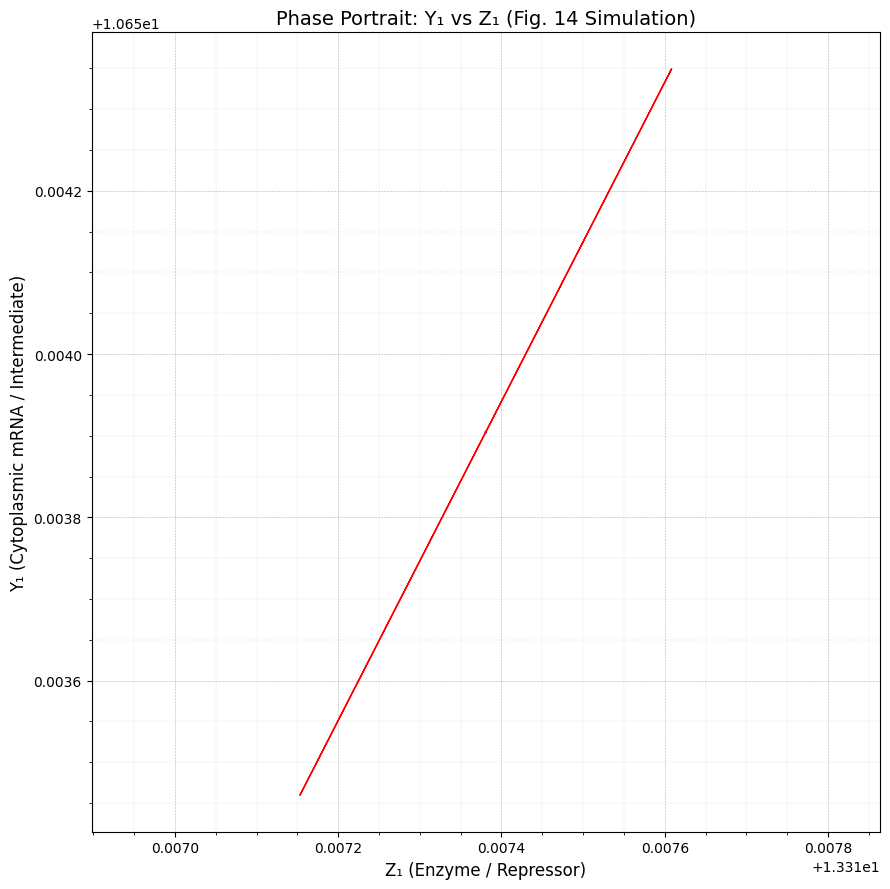


--- Generating Figure 15: Feedback Inhibition Interpretation ---
Displaying Figure 15. Close plot window to end script.


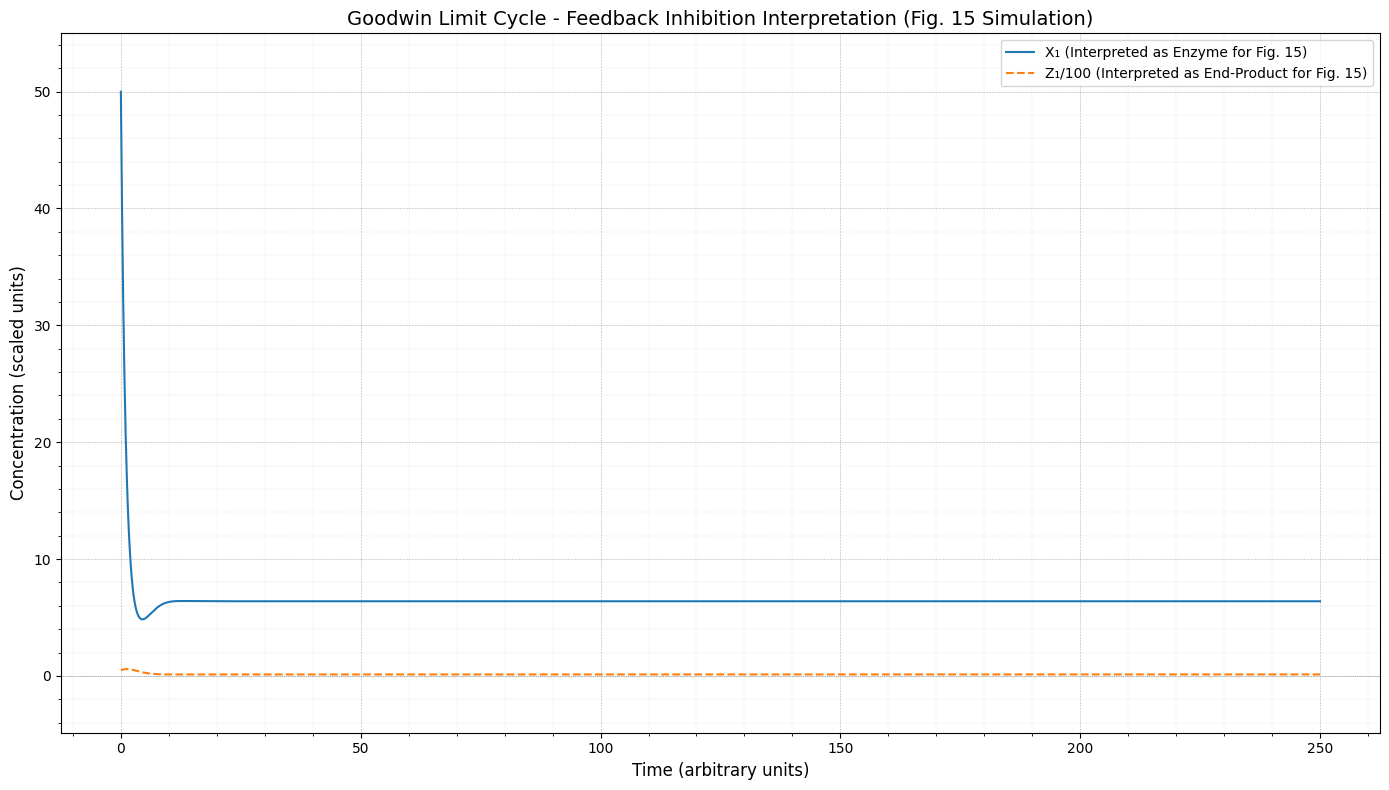


All plots generated.


In [3]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# --- Model Definition (Equations 3 from paper, p.434) ---
def goodwin_limit_cycle_eq3(t, state, p):
    """
    Implements the 3-variable Goodwin model with first-order decay for X, Y, Z.
    (Paper's Equations 3)
    state = [X, Y, Z]
    p = parameter dictionary ('a', 'A', 'k', 'b', 'alpha', 'beta', 'gamma', 'delta')
        Note: 'b' here corresponds to 'b1' in the paper's dX1/dt = ... - b1*X1
    """
    X, Y, Z = state

    # Repression term using Z for X's production
    denominator = p['A'] + p['k'] * Z
    epsilon = 1e-9 # To prevent division by zero if Z makes denominator too small
    if denominator <= epsilon:
        denominator = epsilon

    # dX/dt = a / (A + k*Z) - b*X  (First-order decay for X)
    dX_dt = (p['a'] / denominator) - (p['b'] * X)

    # dY/dt = alpha*X - beta*Y
    dY_dt = p['alpha'] * X - p['beta'] * Y

    # dZ/dt = gamma*Y - delta*Z
    dZ_dt = p['gamma'] * Y - p['delta'] * Z

    return [dX_dt, dY_dt, dZ_dt]

# --- Parameters for Figure 13 (from paper, p.435) ---
# Original paper parameters: a1=360, k1=1, A1=43, b1=1, alpha1=1, beta1=0.6, gamma1=1, delta1=0.8
params_fig13 = {
    'a': 360.0,  # a1 in paper
    'A': 43.0,   # A1 in paper
    'k': 1.0,    # k1 in paper (for repression by Z1)
    'b': 1.0,    # b1 in paper (for X1 decay: -b1*X1)
    'alpha': 1.0,# alpha1 in paper
    'beta': 0.6, # beta1 in paper
    'gamma': 1.0,# gamma1 in paper
    'delta': 0.8 # delta1 in paper
}

# --- Simulation ---
# Initial conditions:
# Let's start perturbed from a potential steady state or use small positive values.
S0_fig13 = [50.0, 50.0, 50.0] # Initial state [X, Y, Z] - Experiment with these values

# Time span
t_max_fig13 = 250 # Adjusted time to observe behavior (original was 200)
t_span_fig13 = (0, t_max_fig13)
# Increase number of points for smoother plots, especially phase portrait
t_eval_fig13 = np.linspace(t_span_fig13[0], t_span_fig13[1], 5000)

# Solve the ODE system
print("Running simulation for Figures 13, 14, 15...")
sol_fig13 = solve_ivp(
    goodwin_limit_cycle_eq3,
    t_span_fig13,
    S0_fig13,
    args=(params_fig13,),
    dense_output=True,
    t_eval=t_eval_fig13,
    method='RK45', # Standard solver
    atol=1e-8, rtol=1e-8 # Tolerances for accuracy
)

# Check solver status and plot
print(f"Solver status: {sol_fig13.status}")
if sol_fig13.status != 0:
    print(f"Solver message: {sol_fig13.message}")

if sol_fig13.success:
    print("Simulation successful. Preparing plots...")
    t = sol_fig13.t
    X, Y, Z = sol_fig13.y

    # --- Figure 13: Time-course oscillations ---
    print("\n--- Generating Figure 13: Time Course ---")
    plt.figure(figsize=(14, 8)) # Slightly larger figure
    plt.plot(t, X, label='X₁ (Nuclear mRNA / Precursor)')
    plt.plot(t, Y, label='Y₁ (Cytoplasmic mRNA / Intermediate)')
    plt.plot(t, Z, label='Z₁ (Enzyme / Repressor)')

    plt.grid(True, which='both', linestyle='--', linewidth=0.4) # Finer grid
    plt.minorticks_on()
    plt.grid(True, which='minor', linestyle=':', linewidth=0.2)

    plt.xlabel("Time (arbitrary units)", fontsize=12)
    plt.ylabel("Concentration (scaled units)", fontsize=12)
    plt.title("Goodwin Limit Cycle Oscillator (Fig. 13 Simulation - Paper Eq. 3)", fontsize=14)
    plt.legend(fontsize=10)
    plt.tight_layout()

    # Ensure the generated_figures directory exists or adjust path
    # For example, if this script is in 'code/', and 'generated_figures' is a sibling:
    # import os
    # if not os.path.exists('../generated_figures'):
    #     os.makedirs('../generated_figures')
    # plt.savefig("../generated_figures/sim_fig_13_limit_cycle_time_course.png")
    plt.savefig("sim_fig_13_limit_cycle_time_course.png") # Saves in current directory

    print("Displaying Figure 13. Please CLOSE this plot window to generate the next plot.")
    plt.show()

    # --- Figure 14: Phase Portrait (Y vs Z) ---
    print("\n--- Generating Figure 14: Phase Portrait (Y vs Z) ---")
    # For better visualization of the limit cycle, plot only the later part of the simulation
    # after transients have died down.
    transient_cutoff_ratio = 0.33 # Discard the first 1/3rd of points
    transient_cutoff_index = int(len(t) * transient_cutoff_ratio)

    plt.figure(figsize=(9, 9)) # Square figure for phase portrait
    # Plotting Y on y-axis and Z on x-axis
    plt.plot(Z[transient_cutoff_index:], Y[transient_cutoff_index:], color='purple')

    # Add an arrow to show the direction of trajectory
    # Pick two points on the later part of the trajectory
    if len(Z[transient_cutoff_index:]) > 200: # Ensure enough points for arrow
        idx1 = len(Z[transient_cutoff_index:]) - 150
        idx2 = len(Z[transient_cutoff_index:]) - 140 # Points further apart for a clearer arrow
        arrow_Z_start = Z[transient_cutoff_index:][idx1]
        arrow_Y_start = Y[transient_cutoff_index:][idx1]
        arrow_dZ = Z[transient_cutoff_index:][idx2] - arrow_Z_start
        arrow_dY = Y[transient_cutoff_index:][idx2] - arrow_Y_start

        # Scale arrow head width based on plot range
        z_range = np.ptp(Z[transient_cutoff_index:])
        head_w = 0.03 * z_range if z_range > 0 else 0.1

        plt.arrow(arrow_Z_start, arrow_Y_start, arrow_dZ, arrow_dY,
                  shape='full', lw=1, length_includes_head=True, head_width=head_w, color='red', zorder=5)

    plt.grid(True, which='both', linestyle='--', linewidth=0.4)
    plt.minorticks_on()
    plt.grid(True, which='minor', linestyle=':', linewidth=0.2)

    plt.xlabel("Z₁ (Enzyme / Repressor)", fontsize=12)
    plt.ylabel("Y₁ (Cytoplasmic mRNA / Intermediate)", fontsize=12)
    plt.title("Phase Portrait: Y₁ vs Z₁ (Fig. 14 Simulation)", fontsize=14)

    # Paper's convention: "positive direction of Z1-axis is from right to left."
    # To match this, uncomment the next line:
    # plt.gca().invert_xaxis()

    plt.axis('equal') # To make spirals/cycles look proportional
    plt.tight_layout()
    plt.savefig("sim_fig_14_phase_portrait_Y_vs_Z.png")

    print("Displaying Figure 14. Please CLOSE this plot window to generate the next plot.")
    plt.show()

    # --- Figure 15: Feedback Inhibition Scaling ---
    print("\n--- Generating Figure 15: Feedback Inhibition Interpretation ---")
    # Paper (p.436): "Figure 15 shows the same basic equations scaled roughly
    # to represent feedback inhibition. The variable showing the sharp peaks
    # and long troughs is then the amount of enzyme, X1, while the other
    # variable shown is the end-product, Z1..."
    # "The scaling used reduces Zx to about 1/100th of its correct value."

    plt.figure(figsize=(14, 8)) # Similar size to Fig 13 plot
    plt.plot(t, X, label='X₁ (Interpreted as Enzyme for Fig. 15)')
    plt.plot(t, Z / 100, label='Z₁/100 (Interpreted as End-Product for Fig. 15)', linestyle='--') # Scaled Z

    plt.grid(True, which='both', linestyle='--', linewidth=0.4)
    plt.minorticks_on()
    plt.grid(True, which='minor', linestyle=':', linewidth=0.2)

    plt.xlabel("Time (arbitrary units)", fontsize=12)
    plt.ylabel("Concentration (scaled units)", fontsize=12)
    plt.title("Goodwin Limit Cycle - Feedback Inhibition Interpretation (Fig. 15 Simulation)", fontsize=14)
    plt.legend(fontsize=10)

    # Adjust y-limits to best show features if necessary
    # This attempts to auto-scale based on plotted data.
    combined_data_fig15 = np.concatenate((X, Z/100))
    min_val_fig15 = np.min(combined_data_fig15)
    max_val_fig15 = np.max(combined_data_fig15)
    padding = 0.1 * (max_val_fig15 - min_val_fig15)
    if padding == 0 and max_val_fig15 == min_val_fig15: padding = 1 # handle flat lines
    elif padding == 0 : padding = 0.1 * abs(max_val_fig15) if max_val_fig15 != 0 else 1


    plt.ylim(min_val_fig15 - padding, max_val_fig15 + padding)
    plt.axhline(0, color='grey', linestyle=':', linewidth=0.5) # Light zero line if relevant

    plt.tight_layout()
    plt.savefig("sim_fig_15_feedback_inhibition_scaled.png")

    print("Displaying Figure 15. Close plot window to end script.")
    plt.show()

    print("\nAll plots generated.")

else:
    print("Simulation for Fig 13/14/15 failed, cannot plot results.")